# Automatic Detection Configuration

## Introduction

Pile driving impacts are detected in the time series using a threshold-based approach.
First, data are high-pass filtered to remove low-frequency noise.
The high-pass filter is a fourth-order Butterworth infinite impulse response filter with a cutoff frequency of 10 Hz.
A characteristic function based on the root-mean-square (RMS) of the filtered signal is computed to aid in detection of pile-driving impacts.
Given the filtered signal $y[n]$, the RMS over a moving window of length $M_1$ is defined as:
\begin{equation}
  y_\mathrm{RMS}[n] = \sqrt{ \frac{1}{M_1}\sum_{k=0}^{M_1-1} y[n-k]^2},
  \tag{1}
\end{equation}
where the window length $M_1$ is chosen to be 25 m/s and:
\begin{equation}
  M_1 = f_s T = \lfloor(\textrm{19100 samples/s})(\textrm{25 m/s})\rfloor = \textrm{488 samples}.
  \tag{2}
\end{equation}
To ensure the threshold used for detecting impulses is consistent across soft start and full power events, the characteristic function is obtained by normalizing Eq. [1] by its running mean computed over the moving window $M_2$:
\begin{equation}
  c[n] = \frac{y_\mathrm{RMS}[n]}{\frac{1}{M_2} \sum_{k=0}^{M_2} y_\mathrm{RMS}[n-k]},
  \tag{3}
\end{equation}
where the window length $M_2$ is chosen to be 5 s and:
\begin{equation}
  M_2 = f_s T = \lfloor(\textrm{19100 samples/s})(\textrm{5 s})\rfloor = \textrm{97656 samples}.
  \tag{4}
\end{equation}
A detection occurs when the characteristic function exceeds a user-defined threshold that is empirically set according to the acoustic environment at each hydrophone.
Triggering is suppressed for 0.75 s before or after a detection to prevent triggering on multipath arrivals.

## Configuration

### Import libraries

In [1]:
import importlib
from pathlib import Path
import sys
import tomllib

from datautils.data import DataStream, read
from datautils.query import CatalogueQuery
from datautils.time import TIME_PRECISION
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj

sys.path.insert(0, str(Path.cwd() / "src"))
import master, plotting

### Set paths to data and logs

In [2]:
EVENT_LOG_PATH = Path("data/logs/events.csv")
SENSORS_PATH = Path("src/config/data.toml")

### Select event

Set the `event_name` variable to the name of the event you want to work with. Possible selections are (all times UTC):

| Event | Start | Stop |
|-------|-------|------|
| `Z01-A` | 2023-06-19T19:20 | 2023-06-19T21:10 |
| `Z01-B` | 2023-06-19T22:25 | 2023-06-19T23:00 |
| `Z01-C` | 2023-06-20T10:35 | 2023-06-20T10:50 |
| `Z01-D` | 2023-06-20T13:15 | 2023-06-20T15:20 |
| `A12-A` | 2023-07-02T17:00 | 2023-07-02T18:20 |
| `A12-B` | 2023-07-02T19:50 | 2023-07-02T21:35 |
| `A08` | 2023-07-06T15:15 | 2023-07-06T18:20 |
| `A10-A` | 2023-07-08T19:00 | 2023-07-08T20:40 |
| `A10-B` | 2023-07-09T10:00 | 2023-07-09T11:30 |
| `A03` | 2023-07-12T19:00 | 2023-07-12T21:50 |
| `A14` | 2023-07-21T20:00 | 2023-07-21T23:50 |
| `A11` | 2023-07-23T20:40 | 2023-07-24T01:20 |
| `A02` | 2023-07-31T19:00 | 2023-07-31T22:20 |
| `A15` | 2023-08-01T20:15 | 2023-08-01T22:50 |
| `A13` | 2023-08-03T14:40 | 2023-08-03T17:40 |
| `A01` | 2023-08-04T15:20 | 2023-08-04T18:25 |
| `A07` | 2023-08-05T21:00 | 2023-08-05T23:55 |
| `A04` | 2023-08-07T10:55 | 2023-08-07T13:45 |

In [3]:
event_name = "A10-B"
event_data = pd.read_csv(EVENT_LOG_PATH).set_index("Event").loc[event_name]
print(event_data)

Start    2023-07-09T10:00
Stop     2023-07-09T11:30
Site                  A10
Lat              41.09339
Lon             -71.12341
Name: A10-B, dtype: object


### Sensors

In [4]:
# Filter type
filter_type = "highpass"
# Filter cutoff freq(s) [Hz]
filter_freq = 10

with open(SENSORS_PATH, "rb") as f:
    sensor_info = tomllib.load(f)["data"]["sensors"]

#### Select Sensor & Channels

Set the `sensor_name` to one of the following and specify the channels you want to work with. Possible selections are:

| Sensor | Channels |
| --- | --- |
| Geosled (`SHRU921_Tetra`) | 0, 1, 2, 3 |
| VLA 1 (`SHRU905_VLA1`) | 0, 1, 2, 3 |
| VLA 2 (`SHRU920_VLA2`) | 0, 1, 2, 3 |

In [5]:
sensor_name = "SHRU921_Tetra"
channels = [0, 1, 2, 3]

#### Load Data

In [6]:
catalogue_path = master.get_catalogue(sensor_info, sensor_name)
cq = CatalogueQuery(
    catalogue=catalogue_path,
    destination=None,
    time_start=np.datetime64(event_data["Start"], TIME_PRECISION),
    time_end=np.datetime64(event_data["Stop"], TIME_PRECISION),
    channels=channels,
)
ds = read(cq)
if filter_type is not None:
    ds = ds.filter(filt_type=filter_type, freq=filter_freq)

#### Plot Full Time Series

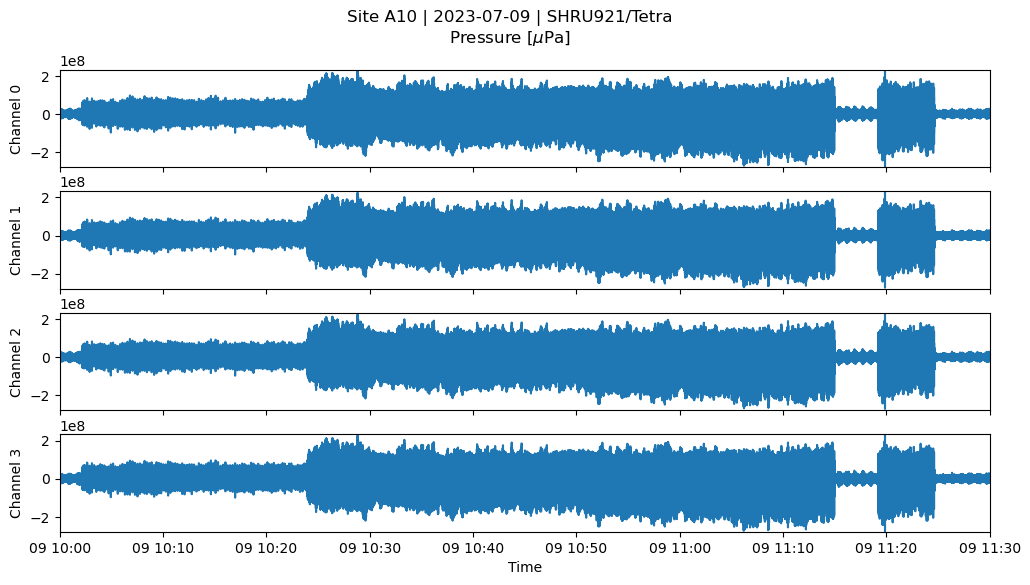

In [18]:
fig = plotting.plot_time_series(
    ds,
    title=f"Site {event_data.Site} | {event_data.Start[0:10]} | {sensor_name.replace('_', '/')}\nPressure [$\\mu$Pa]",
)
# fig.savefig(path / f"time-series_{sensor_name}.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

#### Plot Spectrogram

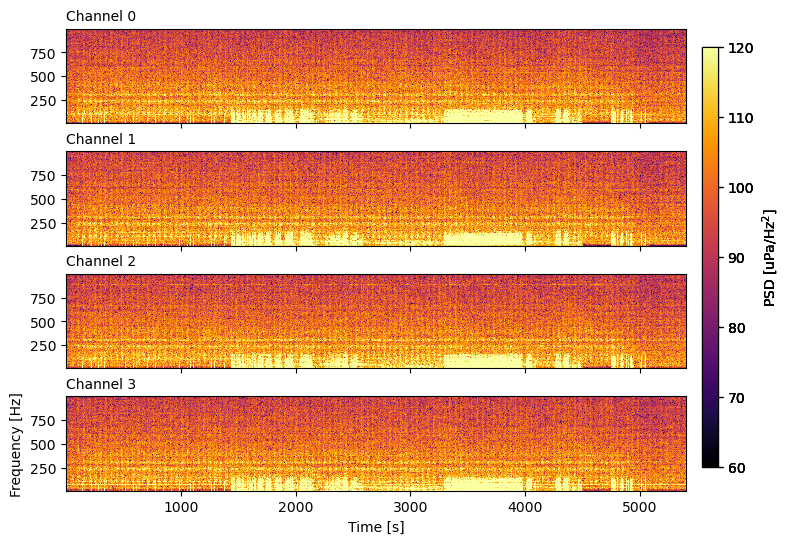

In [19]:
fig = plotting.plot_spectrograms(
    ds,
    fmin=10,
    fmax=1000,
    vmin=60,
    vmax=120,
)
# fig.savefig(path / f"spectrogram_{sensor_name}.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

#### Detection Diagnostics

In [21]:
importlib.reload(plotting)

<module 'plotting' from '/Users/wfjenkins/Research/Projects/RODEOII/src/plotting.py'>

Processing channel 0...
Channel 0 complete.


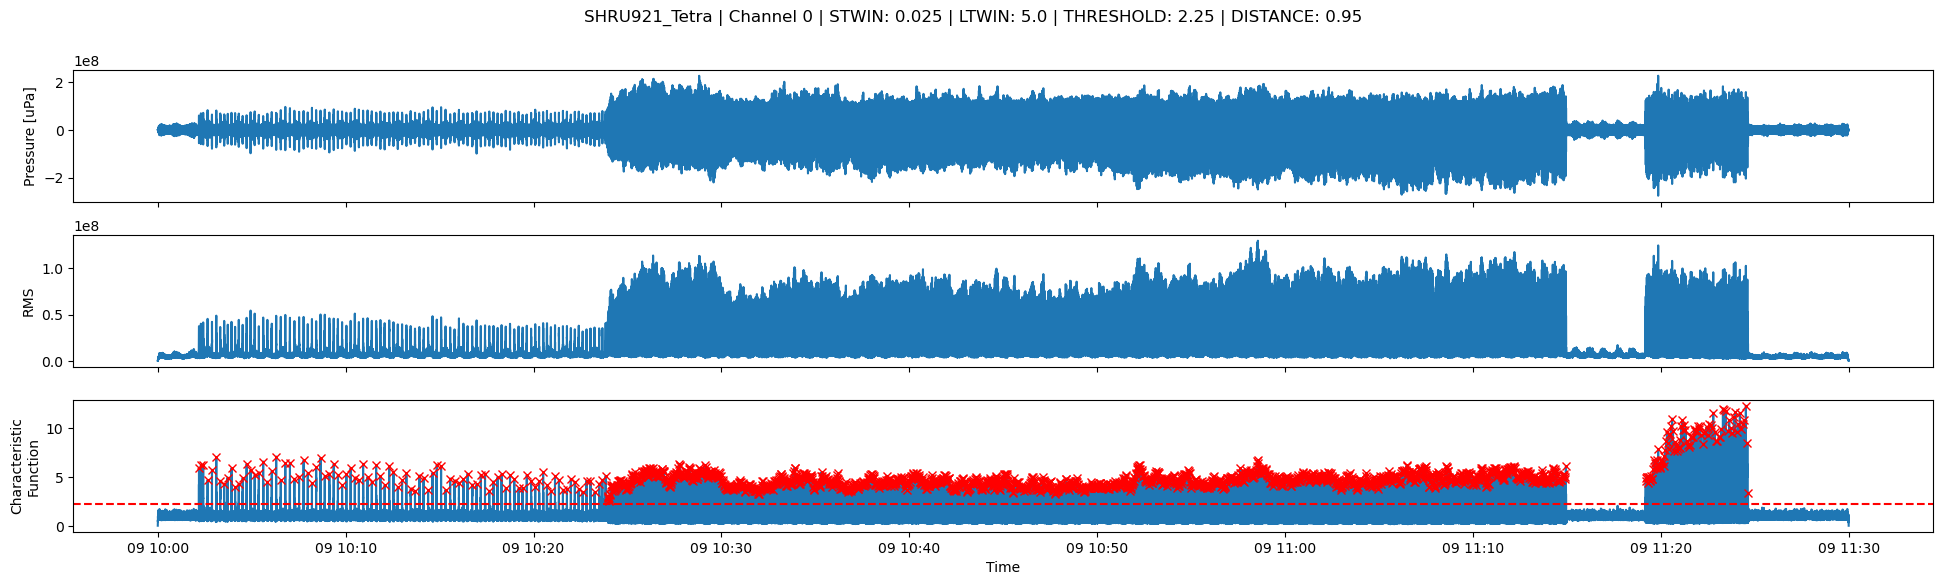

In [22]:
stwin = [0.025, 0.025, 0.025, 0.025]
ltwin = [5.0, 5.0, 5.0, 5.0]
threshold = [2.25, 2.25, 2.25, 2.25]
distance = [0.95, 0.95, 0.95, 0.95]
taper = 5.0

fig = plotting.plot_detection_diagnostic(
    ds,
    stwin=stwin,
    ltwin=ltwin,
    threshold=threshold,
    distance=distance,
    taper=taper,
    sensor=sensor_name,
    channel=0,
)

Processing channel 1...
Channel 1 complete.


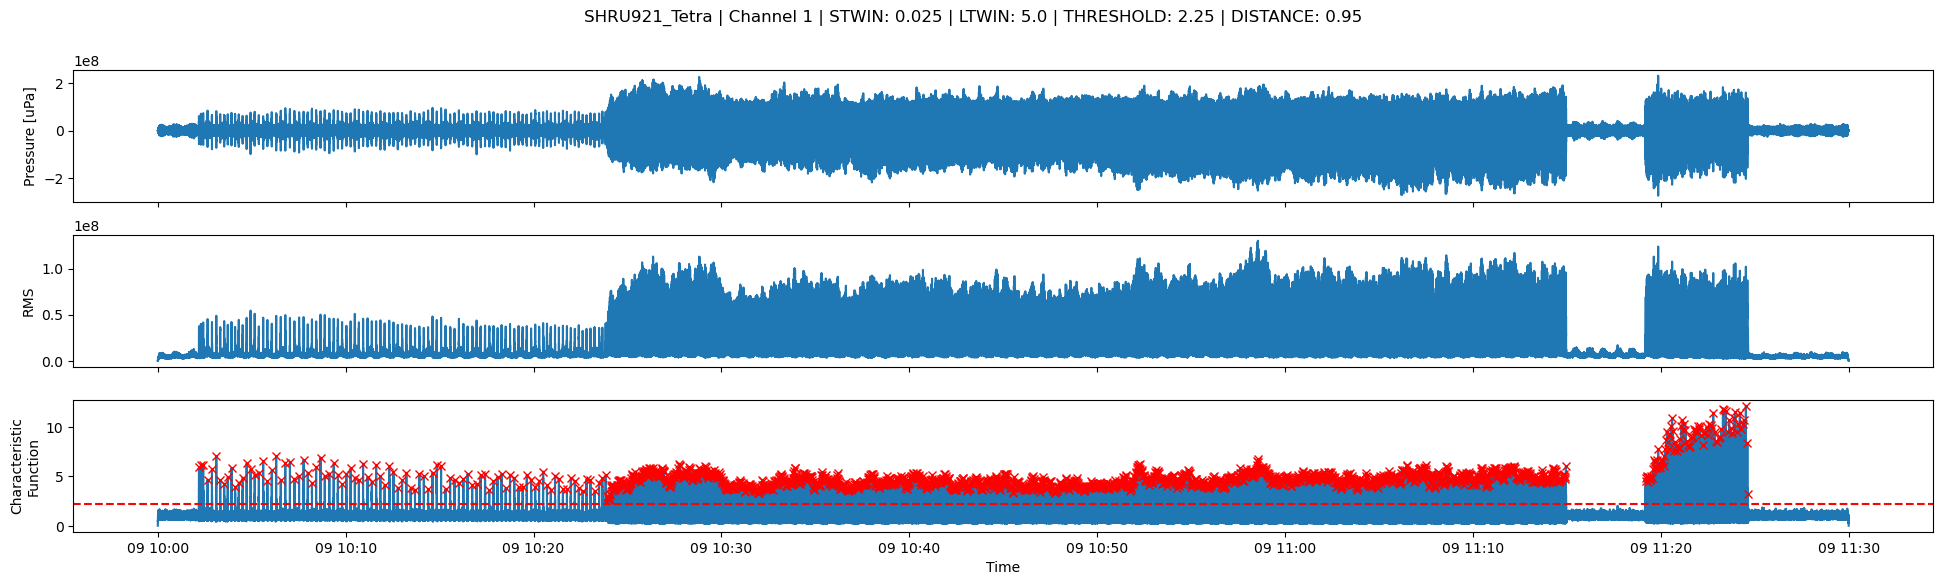

In [7]:
stwin = [0.025, 0.025, 0.025, 0.025]
ltwin = [5.0, 5.0, 5.0, 5.0]
threshold = [2.25, 2.25, 2.25, 2.25]
distance = [0.95, 0.95, 0.95, 0.95]
taper = 5.0

fig = plotting.plot_detection_diagnostic(
    ds,
    stwin=stwin,
    ltwin=ltwin,
    threshold=threshold,
    distance=distance,
    taper=taper,
    sensor=sensor_name,
    channel=1,
)

Processing channel 2...
Channel 2 complete.


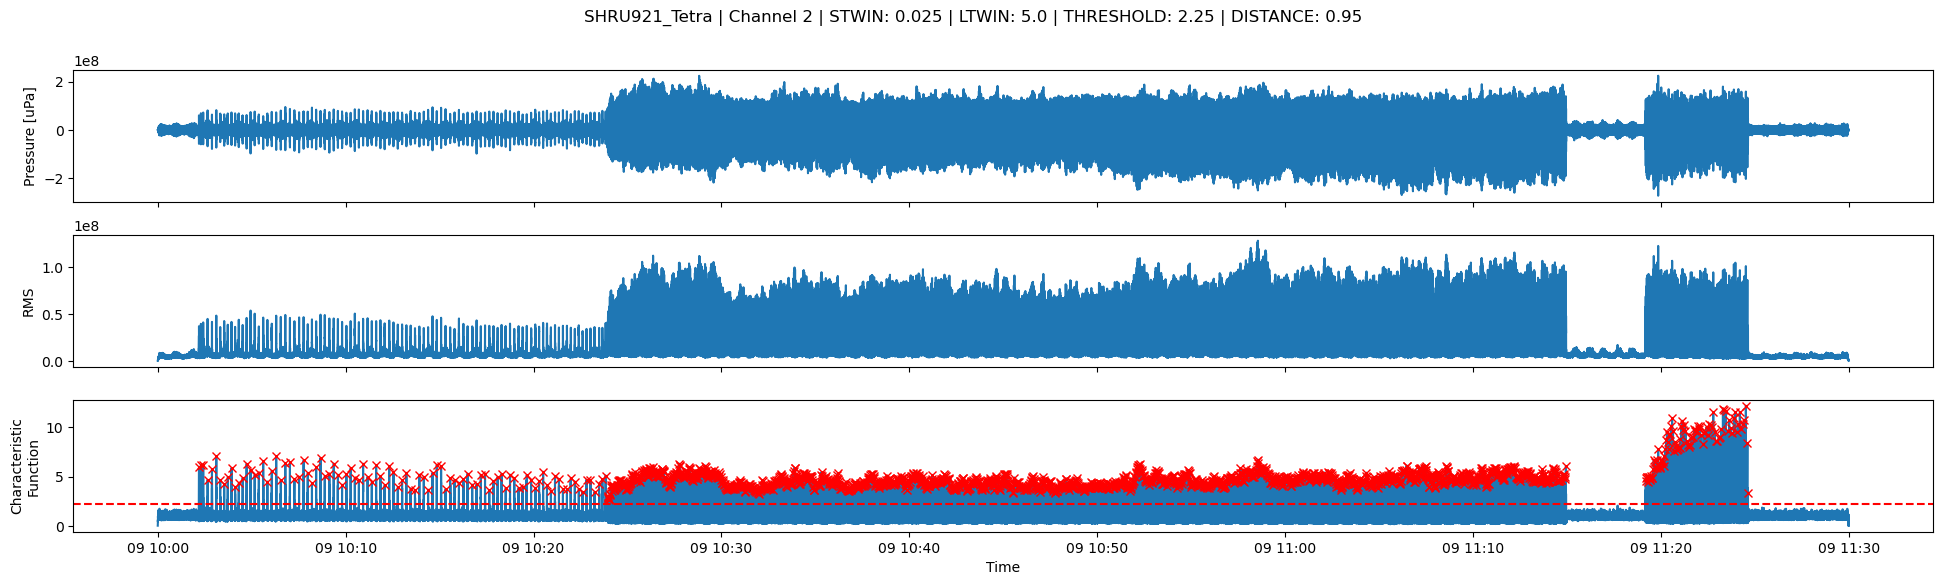

In [7]:
stwin = [0.025, 0.025, 0.025, 0.025]
ltwin = [5.0, 5.0, 5.0, 5.0]
threshold = [2.25, 2.25, 2.25, 2.25]
distance = [0.95, 0.95, 0.95, 0.95]
taper = 5.0

fig = plotting.plot_detection_diagnostic(
    ds,
    stwin=stwin,
    ltwin=ltwin,
    threshold=threshold,
    distance=distance,
    taper=taper,
    sensor=sensor_name,
    channel=2,
)

Processing channel 3...
Channel 3 complete.


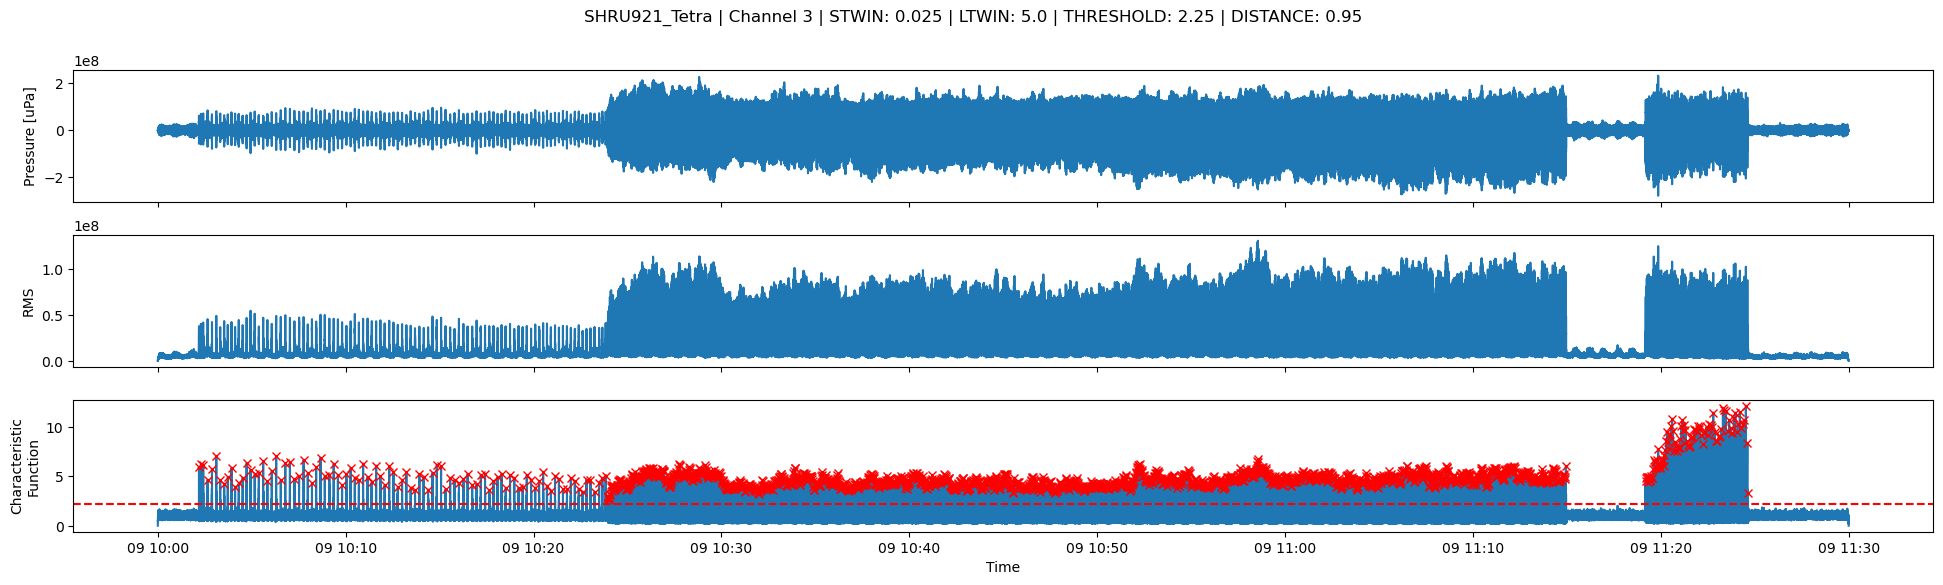

In [7]:
stwin = [0.025, 0.025, 0.025, 0.025]
ltwin = [5.0, 5.0, 5.0, 5.0]
threshold = [2.25, 2.25, 2.25, 2.25]
distance = [0.95, 0.95, 0.95, 0.95]
taper = 5.0

fig = plotting.plot_detection_diagnostic(
    ds,
    stwin=stwin,
    ltwin=ltwin,
    threshold=threshold,
    distance=distance,
    taper=taper,
    sensor=sensor_name,
    channel=3,
)